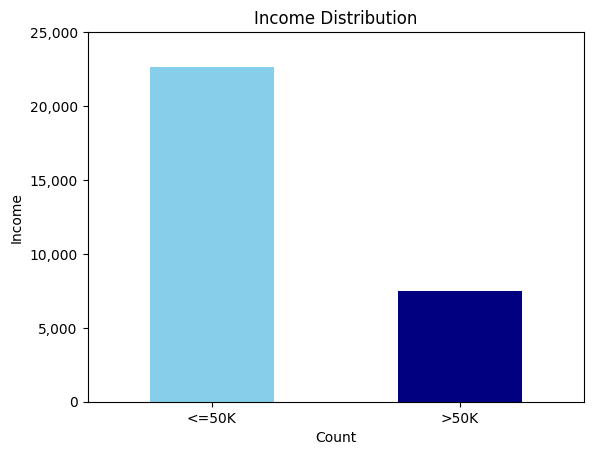

/tmp/ipykernel_5142/3862956258.py:29: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['income'] = df['income'].replace({


(24129, 96)
(6033, 96)
(24129,)
(6033,)
Decision Tree Accuracy: 80.36%
K-Nearest Neighbor Accuracy: 80.74%
Random Forest Accuracy: 84.0%
Top 5 important features in Random Forest:


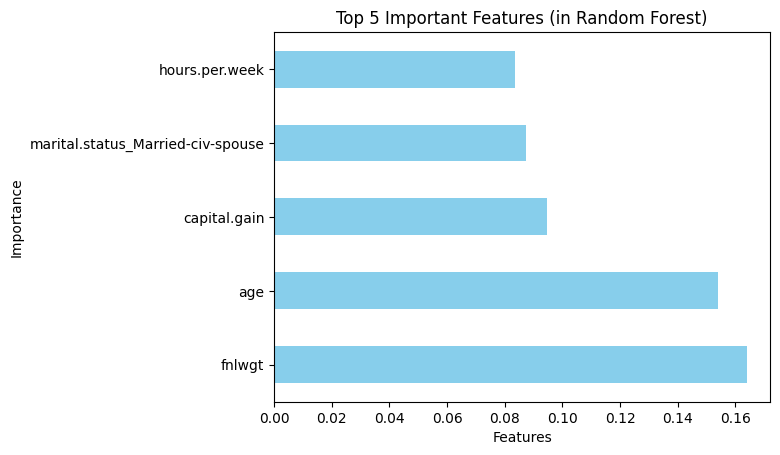

<function matplotlib.pyplot.show(close=None, block=None)>

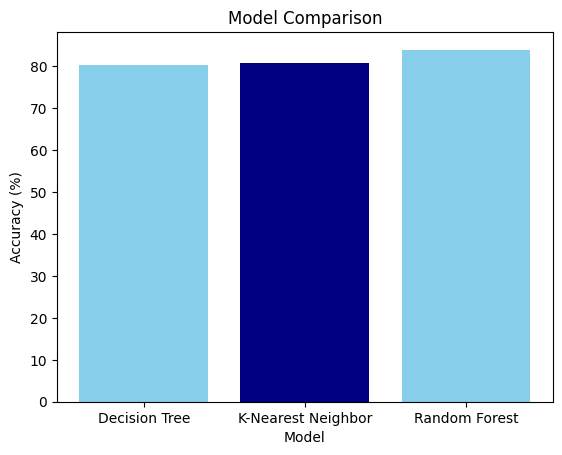

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("adult.csv")
# df.head()
df['income'].value_counts()

# --- Cleaning Data: ---
df = df.replace('?', np.nan) # looked this up
                             # replace '?' with "nan"
df = df.dropna() # drop "nan"

# --- visualize number of people with income ---
import matplotlib.pyplot as plt
df['income'].value_counts().plot.bar(color = ['skyblue', 'navy'])
plt.title("Income Distribution")
plt.xlabel('Count')
plt.xticks(rotation = 0)
plt.ylabel('Income')
y_values = [0, 5000, 10000, 15000, 20000, 25000]
labels_for_y = ['0', '5,000', '10,000', '15,000', '20,000', '25,000']
plt.yticks(y_values, labels_for_y)
plt.show()
# ----------------------------------------------

df['income'] = df['income'].str.strip()
# df.loc[df['income'] == '>50k', 'income'] = 1  # set '>50K' to 1
# df.loc[df['income'] == '<=50k', 'income'] = 0 # set '<=50K' to 0
df['income'] = df['income'].replace({
    '>50K': 1, # replace '>50K' with 1
    '<=50K': 0 # replace '<=50K' with 0
})
df['income'] = df['income'].astype(int)
# df.head()

df = pd.get_dummies(df, drop_first = True)
# df.head()

X = df.drop('income', axis = 1)
Y = df['income']
# X.head()
# Y.head()

# split dataset into training and testing set
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2)

print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

# --- Model 1: Decision Tree ---
# Taken help from documentation
from sklearn.tree import DecisionTreeClassifier
# create and train model
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train, Y_train)
# make prediction
Y_prediction = decision_tree.predict(X_test)
# measure accuracy
from sklearn.metrics import accuracy_score # looked this up
decisiontree_accuracy = (accuracy_score(Y_test, Y_prediction) * 100) # convert to percent (*100)
# decision_tree_accuracy = decision_tree_accuracy.round(2)
decisiontree_accuracy = round(decisiontree_accuracy, 2) # round up to 2 dp

print("Decision Tree Accuracy: ", decisiontree_accuracy, "%", sep = "")
# ------------------------------

# --- Model 2: KNN ---
# Taken help from documentation
from sklearn.preprocessing import StandardScaler # looked this up
from sklearn.neighbors import KNeighborsClassifier
# scale data
scaler_for_data = StandardScaler()
scaler_for_data.fit(X_train) # looked this up
X_train_scaled = scaler_for_data.transform(X_train)
X_test_scaled = scaler_for_data.transform(X_test)
# create and train model
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled, Y_train)
# make prediction
Y_prediction_knn = knn_model.predict(X_test_scaled)
# measure accuracy
from sklearn.metrics import accuracy_score
knn_accuracy = (accuracy_score(Y_test, Y_prediction_knn) * 100) # convert to percent (*100)
knn_accuracy = round(knn_accuracy, 2) # round up to 2 dp

print("K-Nearest Neighbor Accuracy: ", knn_accuracy, "%", sep = "")
# --------------------

# --- Model 3: Random Forest ---
# Taken help from documentation
from sklearn.ensemble import RandomForestClassifier
# create and train model
random_forest_model = RandomForestClassifier()
random_forest_model.fit(X_train, Y_train)
# make prediction
Y_prediction_randomforest = random_forest_model.predict(X_test)
# measure accuracy
from sklearn.metrics import accuracy_score
randomforest_accuracy = (accuracy_score(Y_test, Y_prediction_randomforest) * 100) # convert to percent (*100)
randomforest_accuracy = round(randomforest_accuracy, 2) # round up to 2 dp

print("Random Forest Accuracy: ", randomforest_accuracy, "%", sep = "")

# --- Important Features ---
# Looked this up (https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html)
importance_in_dataset = random_forest_model.feature_importances_
feature_names = list(X.columns)
important_series = pd.Series(importance_in_dataset, feature_names)
important_series = important_series.sort_values(ascending = False)
print("Top 5 important features in Random Forest:")
top_5_features = important_series.head()
# plot Important Features
plt.figure()
top_5_features.plot(kind = "barh", color = "skyblue")
plt.title("Top 5 Important Features (in Random Forest)")
plt.xlabel("Features")
# x_values = ["fnlwgt", "age", "capital.gain", "hours.per.week", "marital.status_Married-civ-spouse"]
# labels_for_x = ["final weight", "age", "capital gain", "hours/week", "marital status"]
# plt.xticks(x_values, labels_for_x, rotation = 0)
plt.ylabel("Importance")
plt.show()
# -----------------------------

# --- Model Comparison ---
model_names = ["Decision Tree", "K-Nearest Neighbor", "Random Forest"]
model_accuracies = [decisiontree_accuracy, knn_accuracy, randomforest_accuracy]
plt.figure()
plt.bar(model_names, model_accuracies, color = ["skyblue", "navy"])
plt.title("Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.show()
# ------------------------